In [65]:
import pandas as pd
import os
path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")


# kagglehub returns the absolute path of the directory containing the dataset files
files = os.listdir(path)
print("Files in dataset directory:", files)

# Find the CSV file inside the directory and load it
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    target_file = os.path.join(path, csv_files[0])
    df = pd.read_csv(target_file)
    print(f"\nSuccessfully loaded {csv_files[0]}!")
else:
    print("No CSV file found in the dataset folder.")

Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Files in dataset directory: ['car data.csv', 'car details v4.csv', 'CAR DETAILS FROM CAR DEKHO.csv', 'Car details v3.csv']

Successfully loaded car data.csv!


In [66]:
print(df.head())
print(df.shape)
print(df.info())
print(df.describe())

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
(301, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price

In [68]:
for col in df.columns:
    print(col, df[col].unique())


Car_Name ['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire' 'alto k10' 'ignis' '800' 'baleno' 'omni'
 'fortuner' 'innova' 'corolla altis' 'etios cross' 'etios g' 'etios liva'
 'corolla' 'etios gd' 'camry' 'land cruiser' 'Royal Enfield Thunder 500'
 'UM Renegade Mojave' 'KTM RC200' 'Bajaj Dominar 400'
 'Royal Enfield Classic 350' 'KTM RC390' 'Hyosung GT250R'
 'Royal Enfield Thunder 350' 'KTM 390 Duke ' 'Mahindra Mojo XT300'
 'Bajaj Pulsar RS200' 'Royal Enfield Bullet 350'
 'Royal Enfield Classic 500' 'Bajaj Avenger 220' 'Bajaj Avenger 150'
 'Honda CB Hornet 160R' 'Yamaha FZ S V 2.0' 'Yamaha FZ 16'
 'TVS Apache RTR 160' 'Bajaj Pulsar 150' 'Honda CBR 150' 'Hero Extreme'
 'Bajaj Avenger 220 dtsi' 'Bajaj Avenger 150 street' 'Yamaha FZ  v 2.0'
 'Bajaj Pulsar  NS 200' 'Bajaj Pulsar 220 F' 'TVS Apache RTR 180'
 'Hero Passion X pro' 'Bajaj Pulsar NS 200' 'Yamaha Fazer '
 'Honda Activa 4G' 'TVS Sport ' 'Honda Dream Yuga '
 'Bajaj Avenger Street 220' 'He

In [69]:
df['Fuel_Type']=df['Fuel_Type'].map({'Petrol':0, 'Diesel':1, 'CNG':2})
df['Transmission']=df['Transmission'].map({'Manual':0, 'Automatic':1})
df['Seller_Type']=df['Seller_Type'].map({'Individual':0, 'Dealer':1, 'Trustmark Dealer':2})


In [72]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301.0,0.212625,0.425801,0.00,0.0,0.0,0.0,2.0
Seller_Type,301.0,0.647841,0.478439,0.00,0.0,1.0,1.0,1.0
Transmission,301.0,0.132890,0.340021,0.00,0.0,0.0,0.0,1.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0


[]

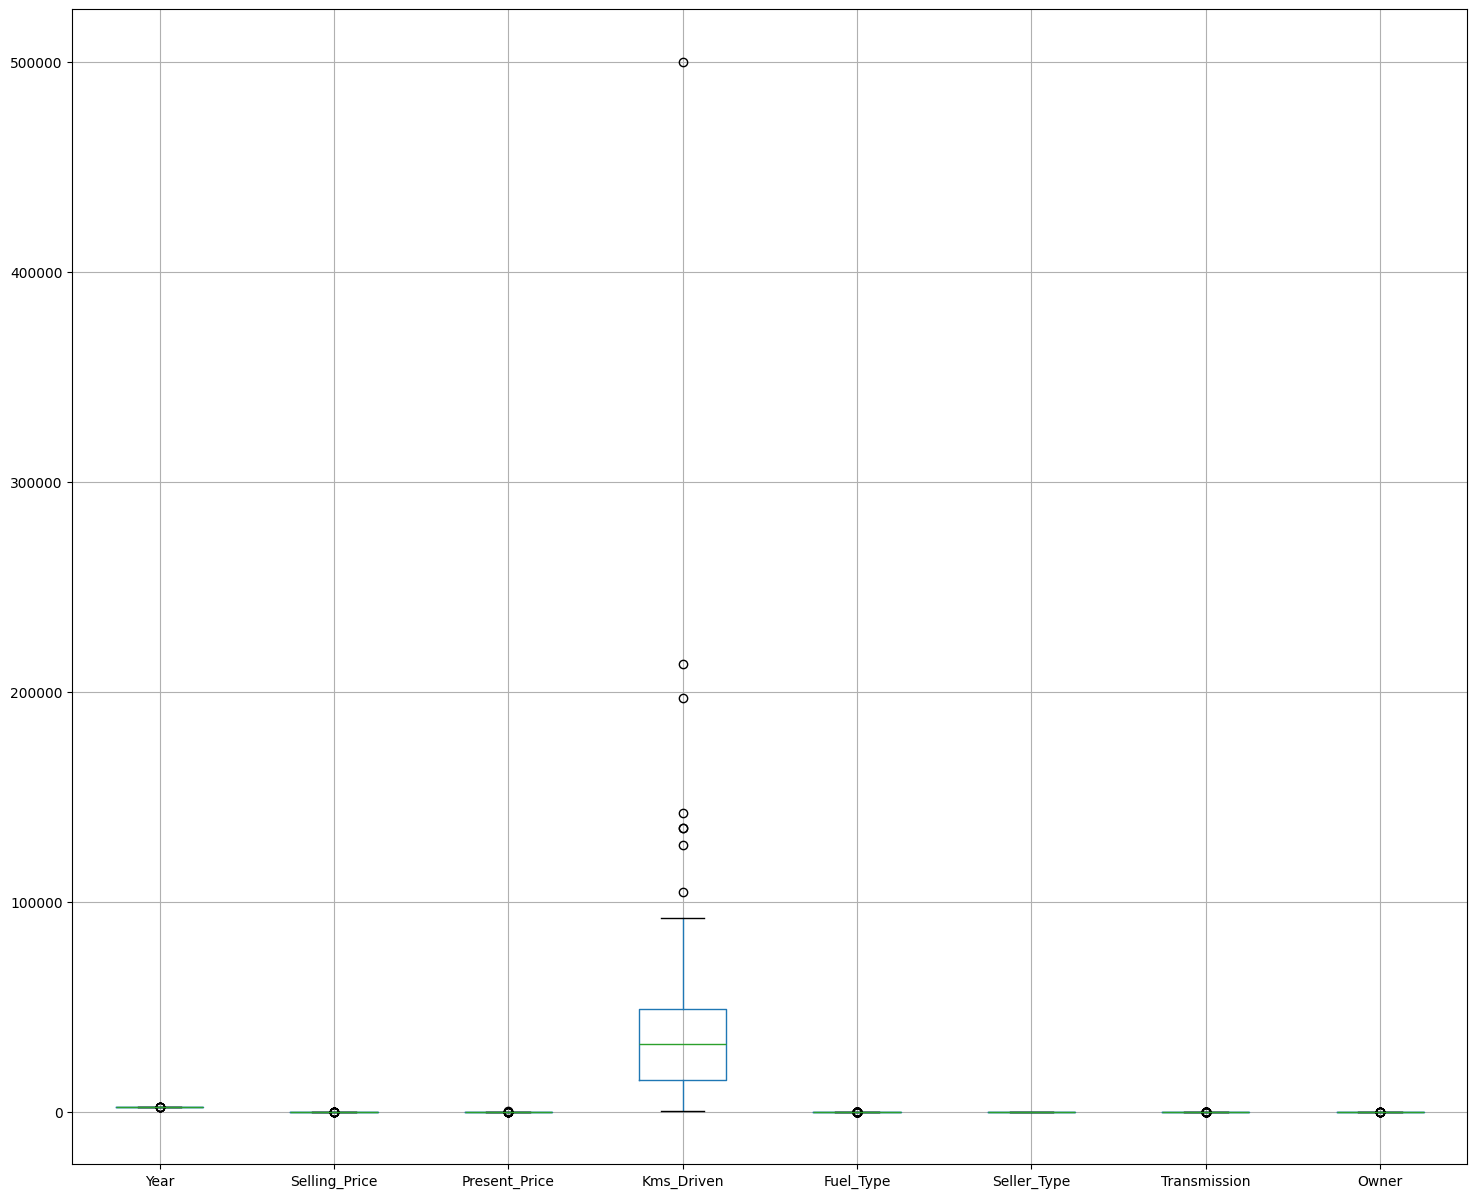

In [74]:
plt.figure(figsize=(18, 15))
df.boxplot()
plt.plot()

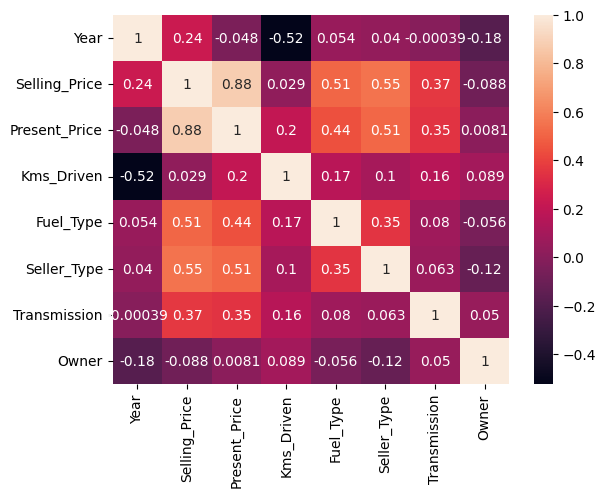

In [76]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [77]:
# Drop the record where Kms_Driven is 500,000
print(f"Rows before dropping outlier: {df.shape[0]}")
df = df[df['Kms_Driven'] != 500000]
print(f"Rows after dropping outlier: {df.shape[0]}")
print(f"New maximum Kms_Driven: {df['Kms_Driven'].max()}")

Rows before dropping outlier: 301
Rows after dropping outlier: 300
New maximum Kms_Driven: 213000


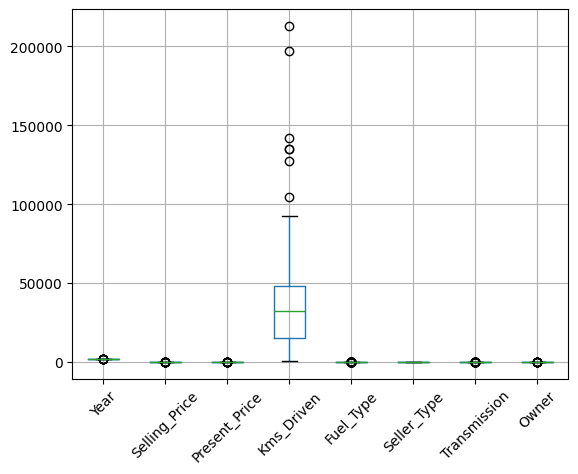

In [80]:
df.boxplot()
plt.xticks(rotation=45)
plt.show()

In [81]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,accuracy_score,mean_squared_error,mean_absolute_error



In [89]:
X =df.drop(columns=['Selling_Price','Car_Name'],axis=1)
y =df['Selling_Price']

In [90]:
X.head()

,Year,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,5.59,27000,0,1,0,0
1,2013,9.54,43000,1,1,0,0
2,2017,9.85,6900,0,1,0,0
3,2011,4.15,5200,0,1,0,0
4,2014,6.87,42450,1,1,0,0


In [91]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [92]:
X_trainScaled =ss.fit_transform(X_train)
X_testScaled =ss.transform(X_test)

In [94]:
lr =LinearRegression()
lr.fit(X_trainScaled,y_train)
ypred =lr.predict(X_testScaled)


print('mean_squared_error :',mean_squared_error(y_test,ypred))
print('mean_absolute_error :',mean_absolute_error(y_test,ypred))
print('r2_score :',r2_score(y_test,ypred))


mean_squared_error : 3.432686922183507
mean_absolute_error : 1.250029876804568
r2_score : 0.8571648240210807


In [95]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge


In [97]:
lassomodel = Lasso()
lassomodel.fit(X_trainScaled,y_train)
ypred =lassomodel.predict(X_testScaled)
print('mean_squared_error :',mean_squared_error(y_test,ypred))
print('mean_absolute_error :',mean_absolute_error(y_test,ypred))
print('r2_score :',r2_score(y_test,ypred))


mean_squared_error : 7.694477252299062
mean_absolute_error : 2.036585245280476
r2_score : 0.6798303960389037


In [101]:

ridgemodel = Ridge(alpha=1.0)
ridgemodel.fit(X_trainScaled,y_train)
ypred =ridgemodel.predict(X_testScaled)
print('mean_squared_error :',mean_squared_error(y_test,ypred))
print('mean_absolute_error :',mean_absolute_error(y_test,ypred))
print('r2_score :',r2_score(y_test,ypred))


mean_squared_error : 3.4442355324729124
mean_absolute_error : 1.2512284222719823
r2_score : 0.8566842827365437
